# Exploratory Data Analysis

## 1. Project Overview

### Project: Predicting Housing Affordability in the United States

This project is developed as part of the Kaggle competition **Predicting Housing Affordability in the U.S.**

The dataset provided through the competition contains housing, income, and demographic information across U.S. ZIP codes for developing a model to predict housing affordability.

### Business Objective

Explore the factors associated with housing affordability across U.S. ZIP codes and develop a regression model capable of predicting affordability levels using housing, income, demographic, and geographic characteristics.

### Target Variable

`AffordabilityPercentageTrue`

Represents the percentage of sampled households in a ZIP code whose housing costs are at or below 30% of their respective household incomes.

### Data Source & Acknowledgment

The dataset was obtained through the Kaggle competition **Predicting Housing Affordability in the U.S.**

- **Platform:** Kaggle
- **Competition:** Predicting Housing Affordability in the U.S.
- **Data files and description:** [Kaggle Competition Data](https://www.kaggle.com/competitions/predicting-housing-affordability-in-the-u-s/data)

Credit for the original dataset belongs to its respective creators and providers. This project uses the competition-provided data for educational and predictive modeling purposes.

## 2. Dataset Overview

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Dejavu Sans'
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)

In [4]:
ROOT_PATH = Path.cwd().resolve().parents[0]
RAW_DATA_PATH = ROOT_PATH / "data" / "raw"

TRAIN_PATH = RAW_DATA_PATH / "train.csv"

In [5]:
df = pd.read_csv(TRAIN_PATH)

print(f"[*] Loaded Training Dataset shape: {df.shape[0]:,} rows and {df.shape[1]:,} columns.")

[*] Loaded Training Dataset shape: 13,660 rows and 18 columns.


In [6]:
df.head(5)

,Zip,Month,SampleSize,State,City,Metro,RentIndex,AnnualMedianHouseholdIncome,OwnerPercent,RenterPercent,MedianHomeLengthofResidence,AvgNumberofChildren,AvgNumberofAdults,AvgHouseholdSize,AvgGenerationsinHousehold,YoungAdultinHouseholdPercent,SeniorAdultinHouseholdPercent,AffordabilityPercentageTrue
0,1002,5/1/2026,8377,MA,Amherst,"Springfield, MA",2465.592738,75709,49.46,50.54,9.0,0.38,1.66,2.00,1.37,6.11,10.09,10
1,1020,5/1/2026,11170,MA,Chicopee,"Springfield, MA",1718.215408,71426,63.70,36.30,12.0,0.61,1.79,2.35,1.53,6.15,12.31,26
2,1040,5/1/2026,13240,MA,Holyoke,"Springfield, MA",1744.615565,55775,42.83,57.17,10.0,0.57,1.66,2.18,1.50,5.14,10.66,8
3,1420,5/1/2026,14248,MA,Fitchburg,"Worcester, MA-CT",1756.207011,75135,51.36,48.64,9.0,0.58,1.75,2.27,1.52,6.98,11.97,8
4,1603,5/1/2026,6615,MA,Worcester,"Worcester, MA-CT",2030.109959,66134,44.89,55.11,9.0,0.49,1.63,2.08,1.43,6.42,9.71,5


In [7]:
print("="*50)
print("1. STRUCTURAL DATA TYPES & NULLS")
print("="*50)
df.info()

1. STRUCTURAL DATA TYPES & NULLS
<class 'pandas.DataFrame'>
RangeIndex: 13660 entries, 0 to 13659
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Zip                            13660 non-null  int64  
 1   Month                          13660 non-null  str    
 2   SampleSize                     13660 non-null  int64  
 3   State                          13660 non-null  str    
 4   City                           13658 non-null  str    
 5   Metro                          13554 non-null  str    
 6   RentIndex                      12475 non-null  float64
 7   AnnualMedianHouseholdIncome    13660 non-null  int64  
 8   OwnerPercent                   13660 non-null  float64
 9   RenterPercent                  13660 non-null  float64
 10  MedianHomeLengthofResidence    13660 non-null  float64
 11  AvgNumberofChildren            13660 non-null  float64
 12  AvgNumberofAdults       

In [8]:
print("="*50)
print("2. SUMMARY STATISTICS ( NUMERICAL )")
print("="*50)
df.drop(columns='Zip').describe().T ## Zip is saved as int in the dataset

2. SUMMARY STATISTICS ( NUMERICAL )


,count,mean,std,min,25%,50%,75%,max
SampleSize,13660.0,10190.726647,5421.856457,151.000000,6220.250000,9446.000000,13331.000000,42755.00000
RentIndex,12475.0,2066.334564,1801.816088,722.931319,1475.183744,1819.242873,2376.644968,97151.63312
AnnualMedianHouseholdIncome,13660.0,94892.364422,38861.228281,14210.000000,67654.000000,87550.500000,114407.000000,322231.00000
OwnerPercent,13660.0,63.927302,17.484670,6.060000,53.360000,66.835000,77.170000,96.83000
RenterPercent,13660.0,36.072704,17.484673,3.170000,22.830000,33.165000,46.640000,93.94000
MedianHomeLengthofResidence,13660.0,9.106040,2.647261,0.000000,7.000000,9.000000,11.000000,15.00000
AvgNumberofChildren,13660.0,0.552783,0.161825,0.060000,0.460000,0.570000,0.660000,1.15000
AvgNumberofAdults,13660.0,1.846474,0.176341,1.090000,1.750000,1.870000,1.970000,2.33000
AvgHouseholdSize,13660.0,2.355083,0.280530,1.230000,2.180000,2.370000,2.540000,3.30000
AvgGenerationsinHousehold,13660.0,1.484803,0.119464,0.860000,1.420000,1.490000,1.570000,1.83000


## 3. Feature Definitions & Data Dictionary

In [9]:

business_definitions = {
    "Zip": ("ZIP Code", "ZIP ID", "Five-digit ZIP code represented by the row. The identifier of this dataset."),
    "Month": ("Month", "mm/dd/yyyy", "The year and month associated with the observation."),
    "SampleSize": ("Household Sample Size", "Household Count", "Number of households represented in the ZIP code sample."),
    "State": ("State", "State Code", "Two-letter state abbreviation."),
    "City": ("Primary City", "Categorical Text", "Primary city associated with the ZIP code."),
    "Metro": ("Metropolitan Area", "Categorical Text", "Metropolitan area associated with the ZIP code."),
    "RentIndex": ("Rent Index", "USD/Month", "Zillow Observed Rent Index for the ZIP code, representing typical monthly asking rent. Source: https://www.zillow.com/research/data/"),
    "AnnualMedianHouseholdIncome": ("Median Annual Household Income", "USD/Year", "Median annual income of households in the ZIP code."),
    "OwnerPercent": ("Homeowner Percentage", "Percent (%)", "Percentage of households classified as homeowners."),
    "RenterPercent": ("Renter Household Percentage", "Percent (%)", "Percentage of households classified as renters."),
    "MedianHomeLengthofResidence": ("Median Residence Tenure", "Years", "Median number of years households have lived at their current residence."),
    "AvgNumberofChildren": ("Average Number of Children per Household", "Children/Household", "Average number of children per household."),
    "AvgNumberofAdults": ("Average Number of Adults per Household", "Adults/Household", "Average number of adults per household."),
    "AvgHouseholdSize": ("Average Household Size", "People/Household", "Average number of people living in each household."),
    "AvgGenerationsinHousehold": ("Average Household Generations", "Generations/Household", "Average number of generations living in each household."),
    "YoungAdultinHouseholdPercent": ("Young Adult Household Percentage", "Percent (%)", "Percentage of households with at least one young adult."),
    "SeniorAdultinHouseholdPercent": ("Senior Adult Household Percentage", "Percent (%)", "Percentage of households with at least one senior adult."),
    "AffordabilityPercentageTrue": ("Housing Affordability Percentage", "Percent (%) - Target Variable", "Percentage of households whose housing costs are 30% or less of their income. The target variable.")
}


In [10]:
dict_list = []

for col in df.columns:
    label, unit, definition = business_definitions.get(col, (col, "N/A", "No definition available"))
    dict_list.append({
        "Feature Name": col,
        "Business Label": label,
        "Data Type": str(df[col].dtype),
        "Unit": unit,
        "Null Count": df[col].isnull().sum(),
        "Unique Values": df[col].nunique(),
        "Business Definition": definition
    })

dict_df = pd.DataFrame(dict_list)
display(dict_df)

,Feature Name,Business Label,Data Type,Unit,Null Count,Unique Values,Business Definition
0,Zip,ZIP Code,int64,ZIP ID,0,6830,Five-digit ZIP code represented by the row. Th...
1,Month,Month,str,mm/dd/yyyy,0,2,The year and month associated with the observa...
2,SampleSize,Household Sample Size,int64,Household Count,0,9626,Number of households represented in the ZIP co...
3,State,State,str,State Code,0,51,Two-letter state abbreviation.
4,City,Primary City,str,Categorical Text,2,3113,Primary city associated with the ZIP code.
5,Metro,Metropolitan Area,str,Categorical Text,106,650,Metropolitan area associated with the ZIP code.
6,RentIndex,Rent Index,float64,USD/Month,1185,12475,"Zillow Observed Rent Index for the ZIP code, r..."
7,AnnualMedianHouseholdIncome,Median Annual Household Income,int64,USD/Year,0,6628,Median annual income of households in the ZIP ...
8,OwnerPercent,Homeowner Percentage,float64,Percent (%),0,5735,Percentage of households classified as homeown...
9,RenterPercent,Renter Household Percentage,float64,Percent (%),0,5736,Percentage of households classified as renters.


In [11]:
REPORT_DIR = ROOT_PATH / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BUSI_DICT = REPORT_DIR / "data_dictionary.csv"

dict_df.to_csv(BUSI_DICT, index=False)

print(f"[+] Exported Business Data Dictionary artifact to: {BUSI_DICT}")

[+] Exported Business Data Dictionary artifact to: S:\Projects\housing_affordability_US\reports\data_dictionary.csv


## 4. Data Quality & Initial Diagnostics

In [12]:
print("=" * 50)
print("\tNUMERICAL FEATURE SKEWNESS")
print("=" * 50)

numeric_df = df.select_dtypes(include=[np.number]).drop(
    columns=['Zip', 'Month'], errors='ignore'
)

skewness_series = numeric_df.skew().sort_values(ascending=False)

skew_summary = pd.DataFrame({
    "Feature": skewness_series.index,
    "Skewness Coefficient": skewness_series.values,
    "Diagnosis": [
        "Extremely Right-Skewed" if s > 3
        else "Moderately Right-Skewed" if s > 1
        else "Extremely Left-Skewed" if s < -3
        else "Moderately Left-Skewed" if s < -1
        else "Not Strongly Skewed"
        for s in skewness_series.values
    ]
})

display(skew_summary)

	NUMERICAL FEATURE SKEWNESS


,Feature,Skewness Coefficient,Diagnosis
0,RentIndex,30.259037,Extremely Right-Skewed
1,AnnualMedianHouseholdIncome,1.259337,Moderately Right-Skewed
2,SampleSize,0.887977,Not Strongly Skewed
3,RenterPercent,0.692962,Not Strongly Skewed
4,SeniorAdultinHouseholdPercent,0.341082,Not Strongly Skewed
5,MedianHomeLengthofResidence,0.268628,Not Strongly Skewed
6,YoungAdultinHouseholdPercent,0.231284,Not Strongly Skewed
7,AffordabilityPercentageTrue,-0.020182,Not Strongly Skewed
8,AvgNumberofChildren,-0.139795,Not Strongly Skewed
9,AvgHouseholdSize,-0.269438,Not Strongly Skewed


In [13]:
print("RentIndex Missingness by Month")
df.groupby('Month')['RentIndex'].agg(
    total='size',
    missing=lambda x: x.isna().sum()
).assign(
    missing_pct=lambda x: x['missing'] / x['total'] * 100
)

RentIndex Missingness by Month


,total,missing,missing_pct
Month,,,
5/1/2026,6830,707,10.351391
6/1/2026,6830,478,6.998536


In [14]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate ZIP-Month combinations: {df.duplicated(['Zip', 'Month']).sum():,}")

Exact duplicate rows: 0
Duplicate ZIP-Month combinations: 0


In [15]:
print("RentIndex Outlier Insepction")
display(df['RentIndex'].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

display(df.nlargest(10, 'RentIndex')[['Zip', 'State', 'City', 'Month', 'RentIndex']])

RentIndex Outlier Insepction


count    12475.000000
mean      2066.334564
std       1801.816088
min        722.931319
1%         910.132945
5%        1103.389620
25%       1475.183744
50%       1819.242873
75%       2376.644968
95%       3488.174509
99%       5058.451523
max      97151.633120
Name: RentIndex, dtype: float64

,Zip,State,City,Month,RentIndex
9082,11976,NY,Water Mill,6/1/2026,97151.63312
1764,11976,NY,Water Mill,5/1/2026,92480.00927
8614,11963,NY,Sag Harbor,6/1/2026,53557.46441
10062,11930,NY,Amagansett,6/1/2026,52564.50811
1045,11963,NY,Sag Harbor,5/1/2026,52309.48071
8844,11968,NY,Southampton,6/1/2026,38755.91146
338,11937,NY,East Hampton,5/1/2026,35303.25930
10063,11937,NY,East Hampton,6/1/2026,35266.90181
98,11968,NY,Southampton,5/1/2026,34264.74022
4038,81611,CO,Aspen,5/1/2026,25661.11210


## 5. Univariate Analysis

In [16]:
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

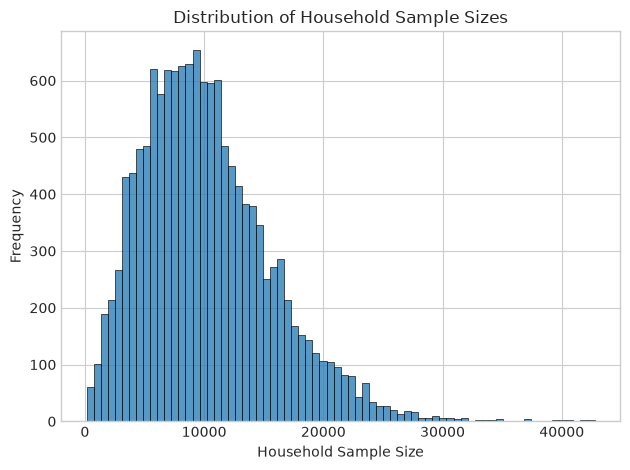

In [17]:
# Sample Size Distribution
sns.histplot(data=df, x="SampleSize")

plt.title("Distribution of Household Sample Sizes")
plt.xlabel("Household Sample Size")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "sample_size_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The household sample size distribution is evaluated across all 13,660 ZIP-Month observations, with each ZIP code represented once per month (May and June). The distribution is concentrated around the mid-range, with the highest frequency occurring near 8,000 households. Frequencies decline as sample sizes increase, with relatively few observations above 17,000. The distribution exhibits positive (right) skewness, indicating that some ZIP-Month observations have substantially larger household sample sizes than the majority.

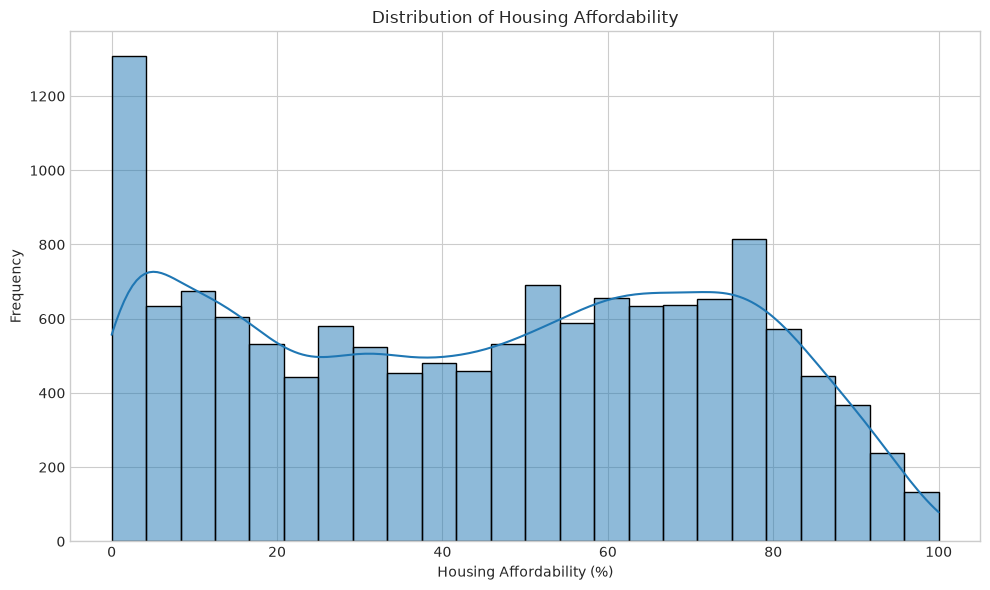

In [18]:
# Target Variable Distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="AffordabilityPercentageTrue",
    kde=True
)

plt.title("Distribution of Housing Affordability")
plt.xlabel("Housing Affordability (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The target variable, `AffordabilityPercentageTrue`, is examined across all 13,660 ZIP-Month observations, with each ZIP code represented once in May and once in June.

The distribution is multimodal and non-normal, featuring a prominent concentration near 0–5% (approximately 1,300 observations) and a secondary elevated region between 50–80%, with a local peak around 75–80%. Frequencies fluctuate throughout the middle range before declining toward 100%.

These patterns indicate substantial variation in housing affordability across the observed ZIP-Month records.

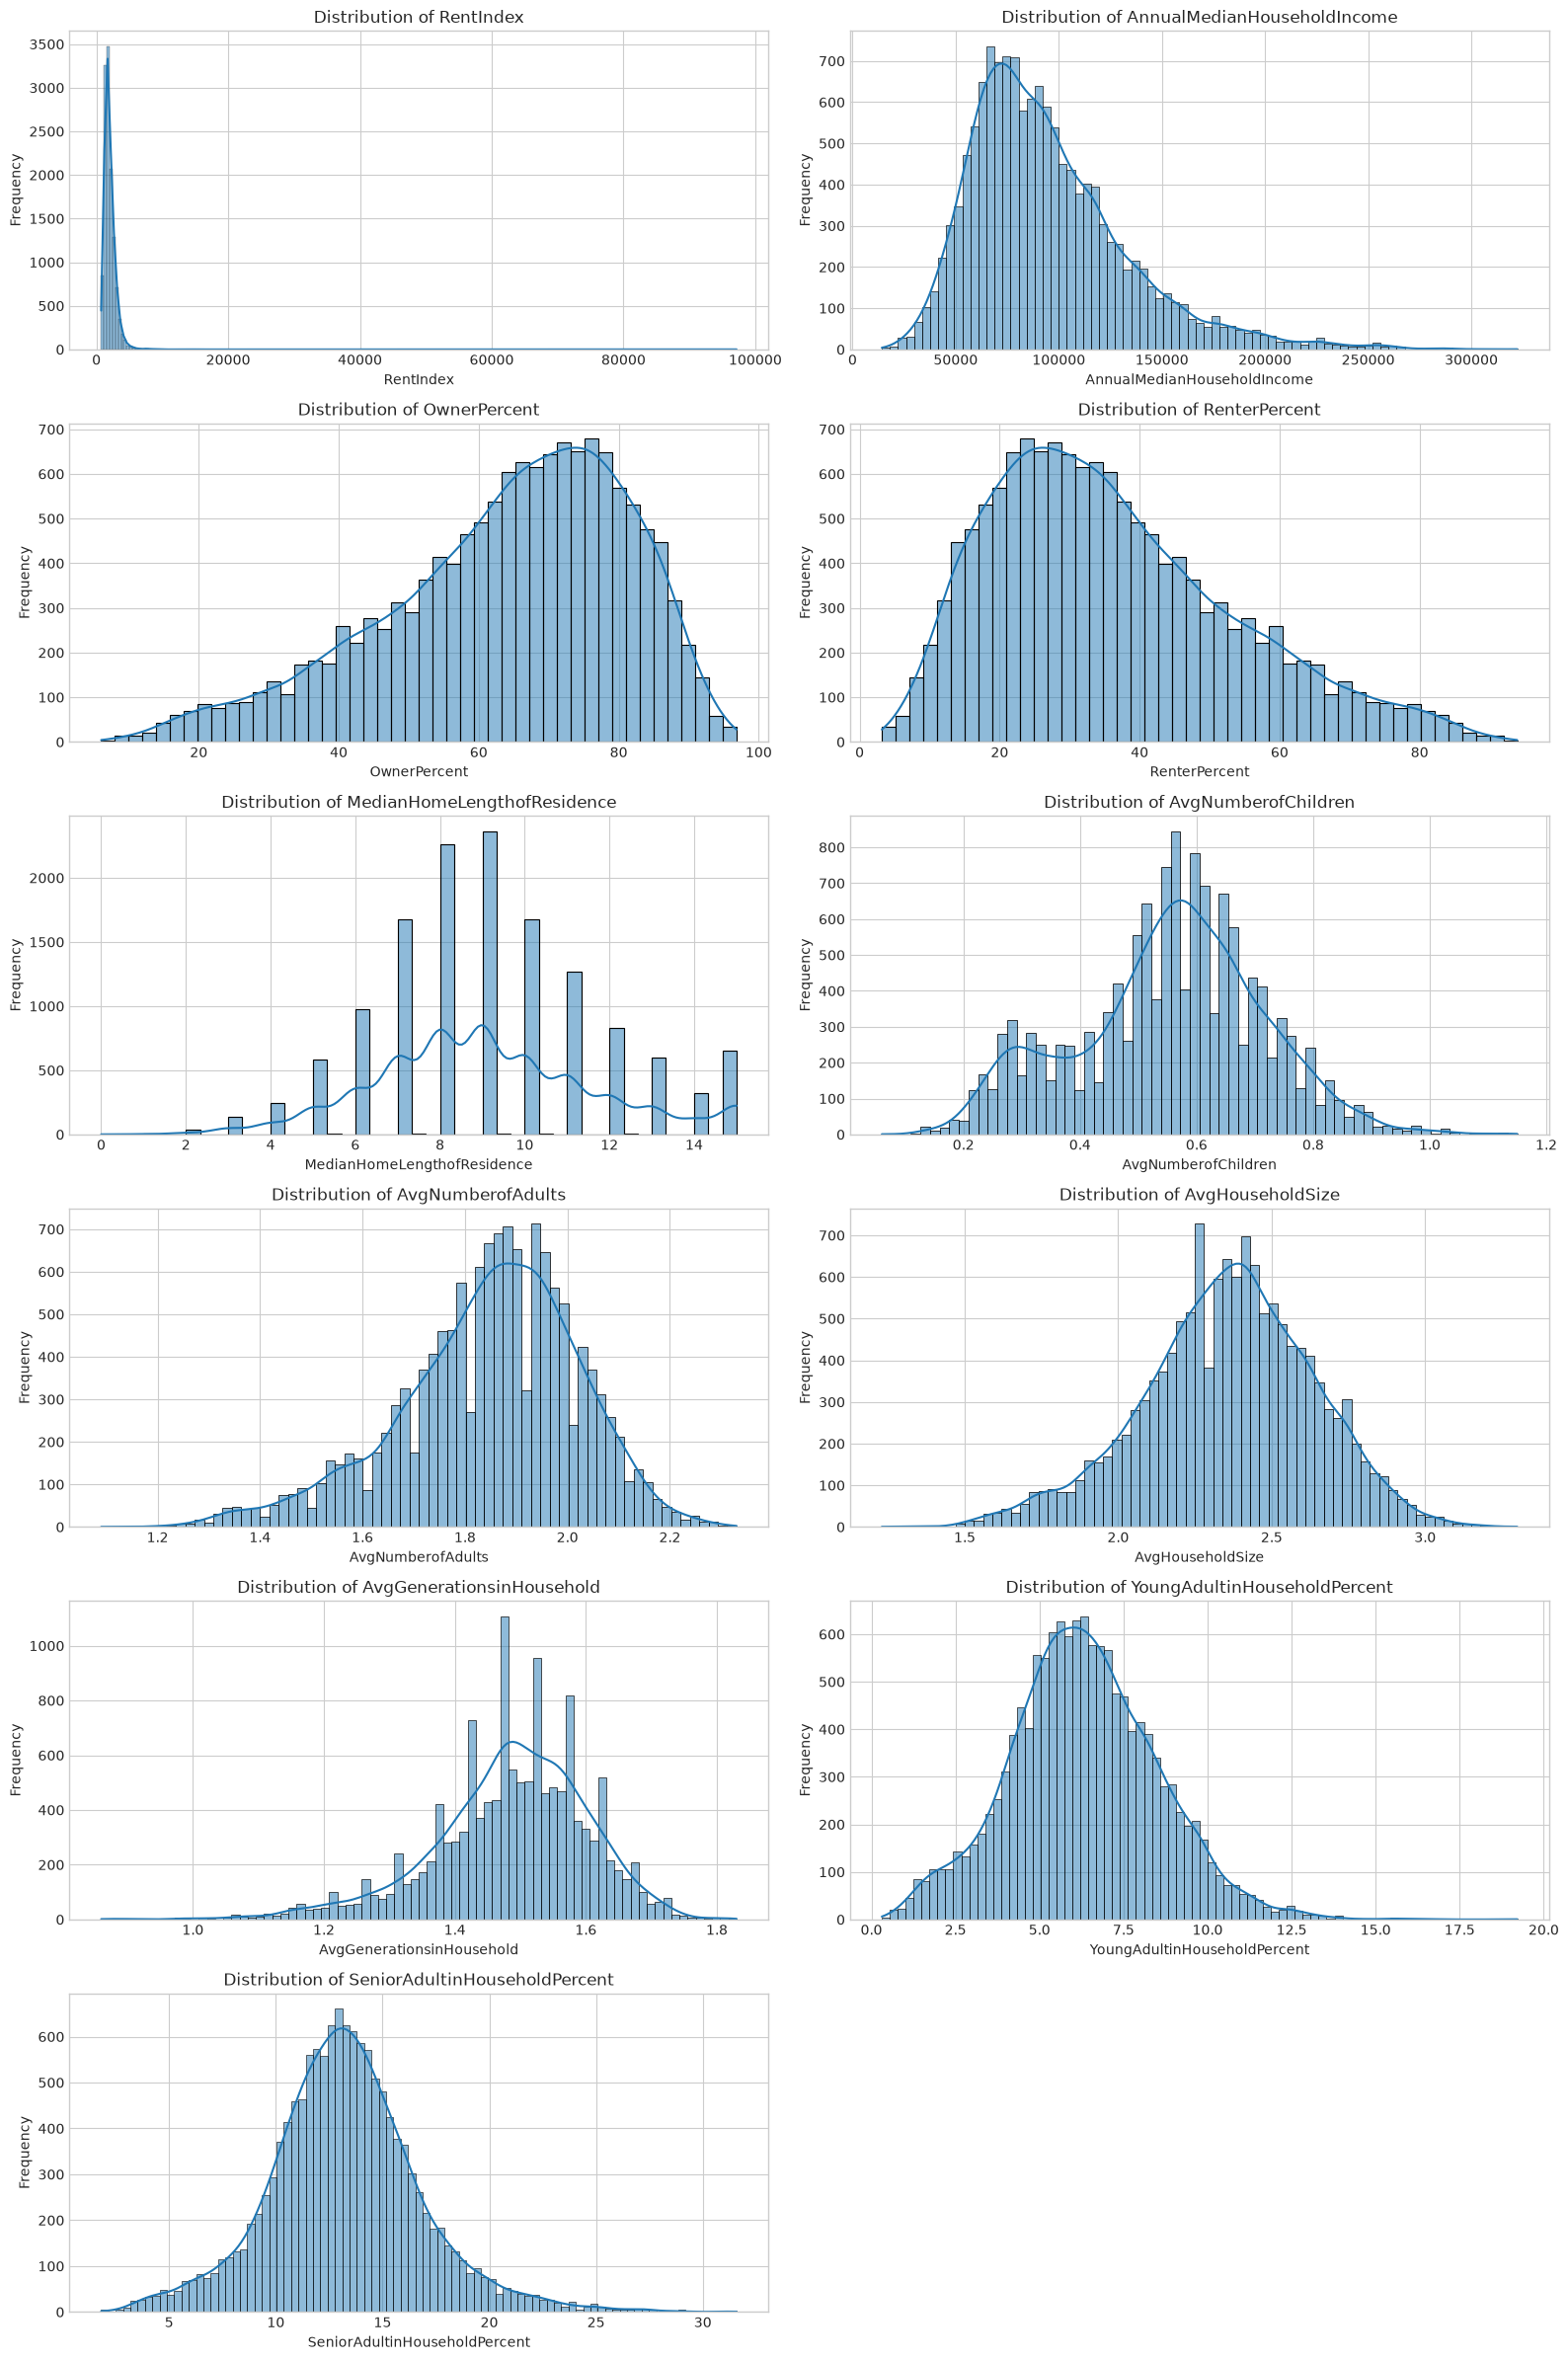

In [19]:
numeric_features = df.select_dtypes(include=[np.number]).columns.drop(
    ['Zip', 'SampleSize', 'AffordabilityPercentageTrue'],
    errors='ignore'
)

n_cols = 2
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

for ax in axes[len(numeric_features):]:
    ax.remove()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "numerical_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The numerical predictor distributions exhibit varying shapes and levels of dispersion across the dataset.

Economic variables, particularly `RentIndex`, display substantial positive skewness, with a small number of observations extending toward considerably higher values. `AnnualMedianHouseholdIncome` also exhibits right skewness, although less pronounced.

The ownership and renter percentages display inverse distribution patterns, reflecting their complementary relationship. `MedianHomeLengthofResidence` exhibits multiple concentration regions, while household demographic variables generally show more concentrated distributions with varying degrees of skewness.

These observations highlight differences in feature distributions and identify variables that may require further investigation during preprocessing.

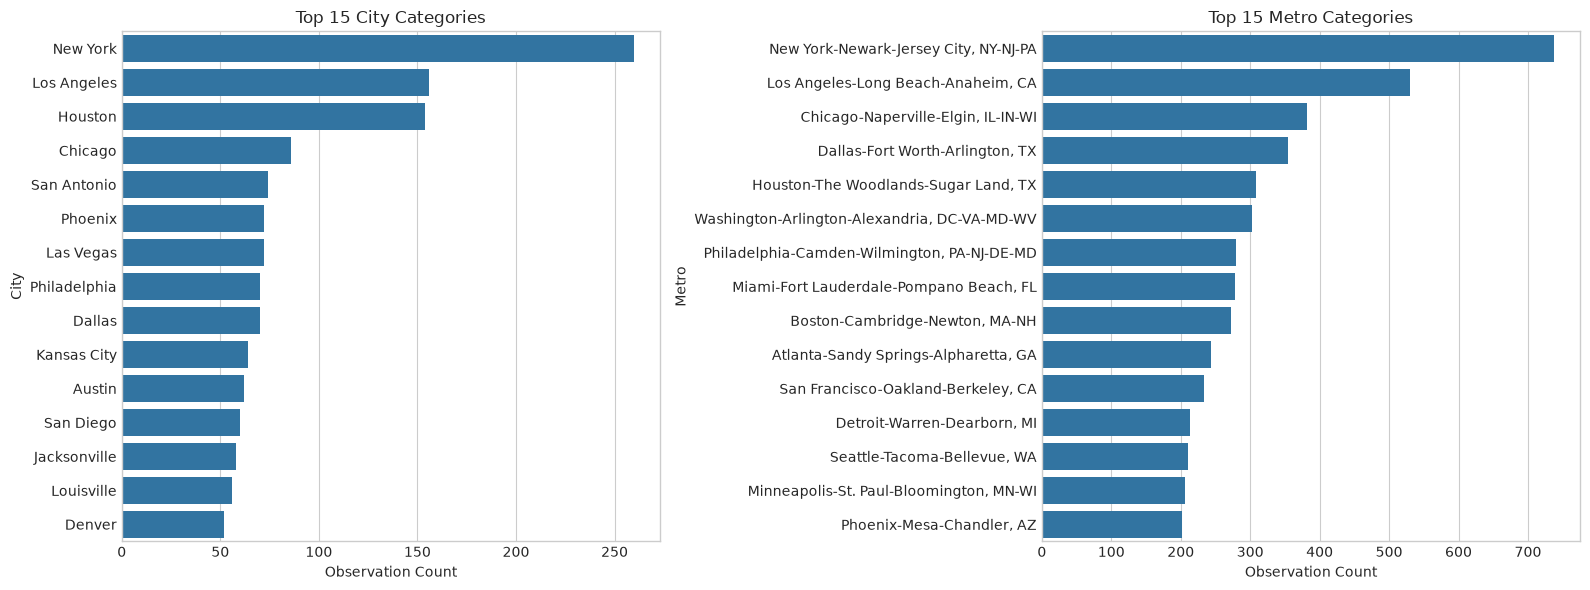

In [20]:
# Categorical Feature Distribution
categorical_features = ['City', 'Metro']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, col in zip(axes, categorical_features):
    top_categories = df[col].value_counts().head(15)

    sns.barplot(
        x=top_categories.values,
        y=top_categories.index,
        ax=ax
    )

    ax.set_title(f'Top 15 {col} Categories')
    ax.set_xlabel('Observation Count')
    ax.set_ylabel(col)

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "categorical_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 6. Geographic Analysis

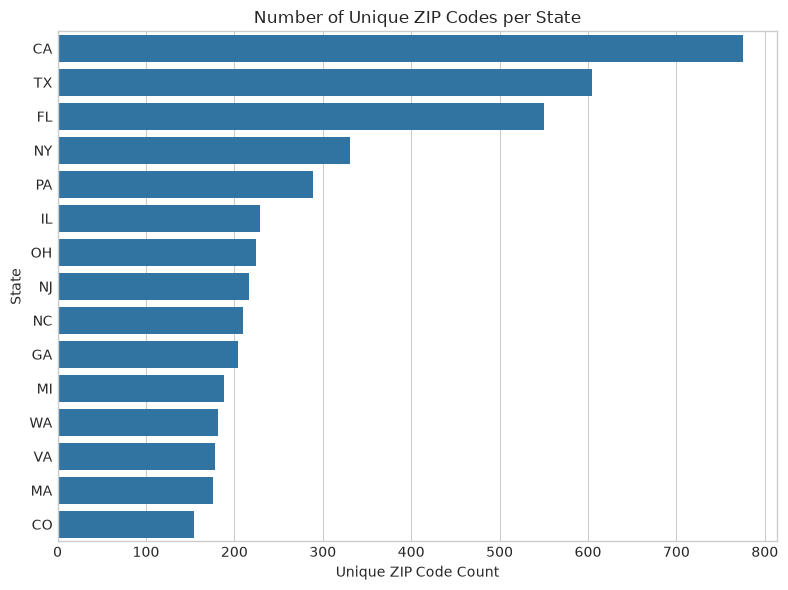

In [21]:
state_zip_counts = (
    df.groupby('State')['Zip']
    .nunique()
    .reset_index(name='ZipCount')
    .sort_values('ZipCount', ascending=False)
    .head(15)
)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(
    data=state_zip_counts.head(15),
    x='ZipCount',
    y='State',
    order=state_zip_counts['State'].head(15)
)

plt.title('Number of Unique ZIP Codes per State')
plt.xlabel('Unique ZIP Code Count')
plt.ylabel('State')
plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "state_zip_code_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


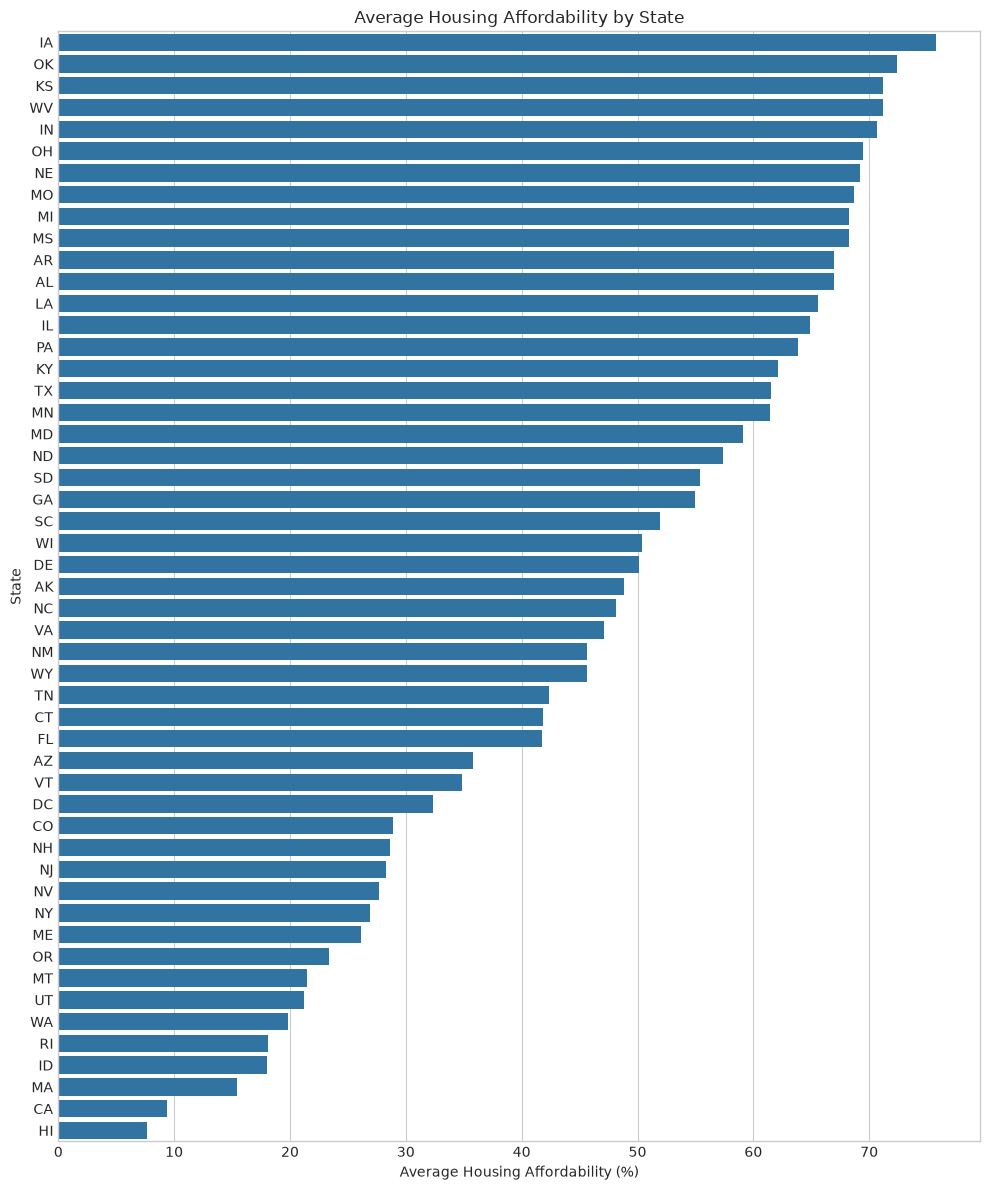

In [22]:
state_affordability = (
    df.groupby('State')['AffordabilityPercentageTrue']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'MeanAffordability', 'count': 'ObservationCount'})
    .sort_values('MeanAffordability', ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 12))

sns.barplot(
    data=state_affordability.reset_index(),
    x='MeanAffordability',
    y='State',
    ax=ax
)

ax.set_title('Average Housing Affordability by State')
ax.set_xlabel('Average Housing Affordability (%)')
ax.set_ylabel('State')

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "average_affordability_by_state.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Average housing affordability varies considerably across states, with higher averages concentrated in some Midwestern states and lower averages in several coastal states.

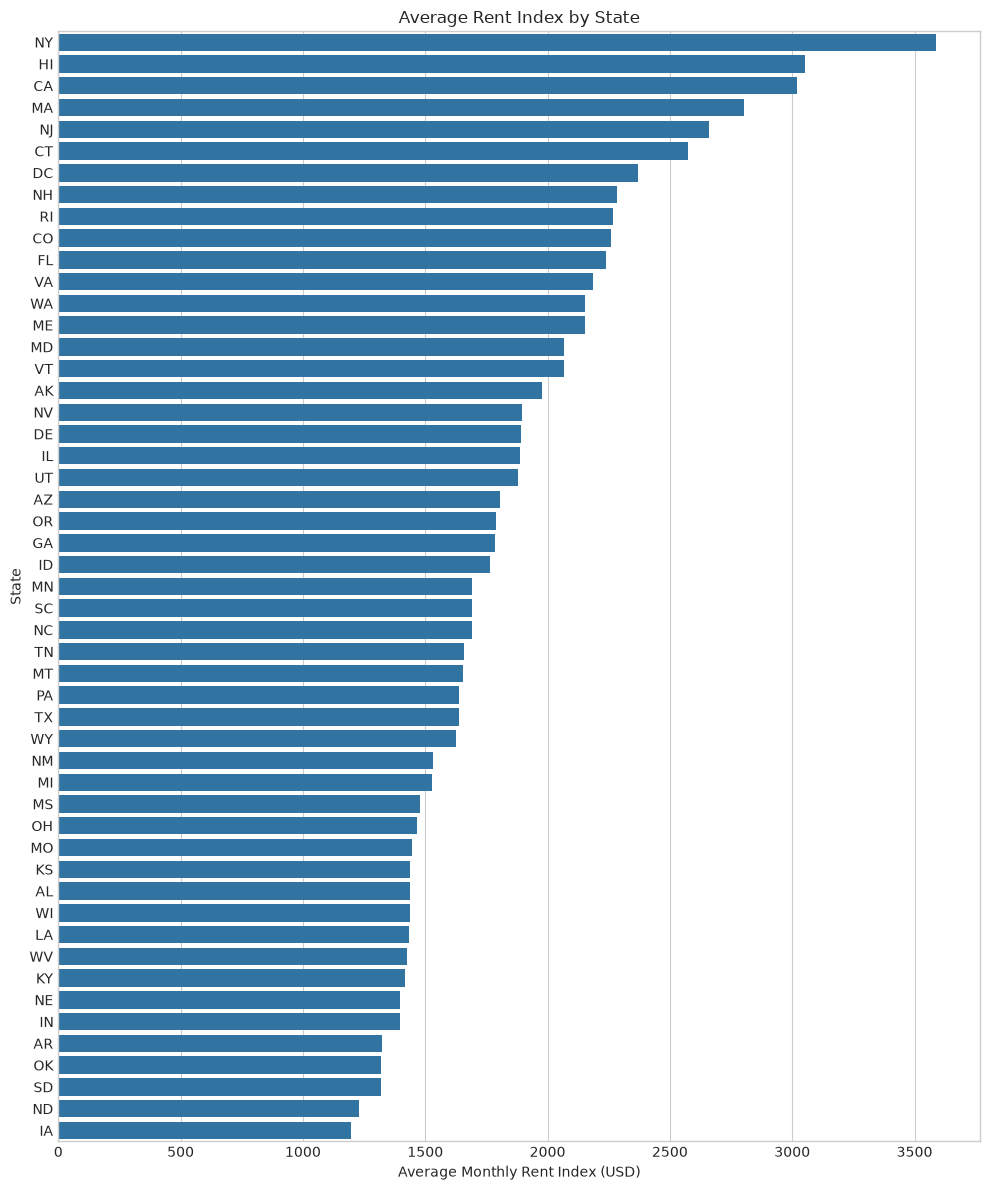

In [23]:
state_rent = (
    df.groupby('State')['RentIndex']
    .mean()
    .sort_values(ascending=False)
    .reset_index(name='MeanRentIndex')
)

fig, ax = plt.subplots(figsize=(10, 12))

sns.barplot(
    data=state_rent,
    x='MeanRentIndex',
    y='State',
    ax=ax
)

ax.set_title('Average Rent Index by State')
ax.set_xlabel('Average Monthly Rent Index (USD)')
ax.set_ylabel('State')

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "average_rent_index_by_state.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Temporal Analysis

In [24]:
monthly_affordability = (
    df.groupby('Month')['AffordabilityPercentageTrue']
    .agg(['mean', 'median'])
    .rename(columns={'mean': 'MeanAffordability', 'median': 'MedianAffordability'})
)

display(monthly_affordability.round(2))

,MeanAffordability,MedianAffordability
Month,,
5/1/2026,44.84,47.0
6/1/2026,44.51,46.0


In [25]:
monthly_rent = (
    df.groupby('Month')['RentIndex']
    .agg(['mean', 'median', 'count'])
    .rename(columns={
        'mean': 'MeanRentIndex',
        'median': 'MedianRentIndex',
        'count': 'ValidObservations'
    })
)

display(monthly_rent.round(2))

,MeanRentIndex,MedianRentIndex,ValidObservations
Month,,,
5/1/2026,2059.21,1817.86,6123
6/1/2026,2073.20,1822.33,6352


## 8. Relationships Between Variables

In [26]:
corr_matrix = df.drop(columns=['Zip', 'Month'], errors='ignore').corr(method='pearson', numeric_only=True)

In [27]:
corr_matrix

,SampleSize,RentIndex,AnnualMedianHouseholdIncome,OwnerPercent,RenterPercent,MedianHomeLengthofResidence,AvgNumberofChildren,AvgNumberofAdults,AvgHouseholdSize,AvgGenerationsinHousehold,YoungAdultinHouseholdPercent,SeniorAdultinHouseholdPercent,AffordabilityPercentageTrue
SampleSize,1.000000,-0.049300,0.017727,0.039408,-0.039409,-0.003093,0.077063,0.107100,0.104899,0.152177,0.177394,0.121820,-0.016311
RentIndex,-0.049300,1.000000,0.368819,0.033029,-0.033029,0.133630,-0.180398,0.074217,-0.053517,-0.040910,0.014474,0.109548,-0.274066
AnnualMedianHouseholdIncome,0.017727,0.368819,1.000000,0.435876,-0.435876,0.126059,0.029087,0.438687,0.301646,0.254383,0.316407,0.248102,-0.199638
OwnerPercent,0.039408,0.033029,0.435876,1.000000,-1.000000,0.110900,0.538943,0.807369,0.819797,0.662615,0.580120,0.444083,0.341056
RenterPercent,-0.039409,-0.033029,-0.435876,-1.000000,1.000000,-0.110900,-0.538943,-0.807369,-0.819797,-0.662615,-0.580121,-0.444083,-0.341055
MedianHomeLengthofResidence,-0.003093,0.133630,0.126059,0.110900,-0.110900,1.000000,-0.093942,0.450121,0.206150,0.348753,0.281722,0.685350,-0.132947
AvgNumberofChildren,0.077063,-0.180398,0.029087,0.538943,-0.538943,-0.093942,1.000000,0.420132,0.826005,0.740308,0.577143,0.132688,0.575856
AvgNumberofAdults,0.107100,0.074217,0.438687,0.807369,-0.807369,0.450121,0.420132,1.000000,0.856914,0.825121,0.803208,0.821188,0.121948
AvgHouseholdSize,0.104899,-0.053517,0.301646,0.819797,-0.819797,0.206150,0.826005,0.856914,1.000000,0.921332,0.816598,0.567627,0.404088
AvgGenerationsinHousehold,0.152177,-0.040910,0.254383,0.662615,-0.662615,0.348753,0.740308,0.825121,0.921332,1.000000,0.855220,0.674216,0.322742


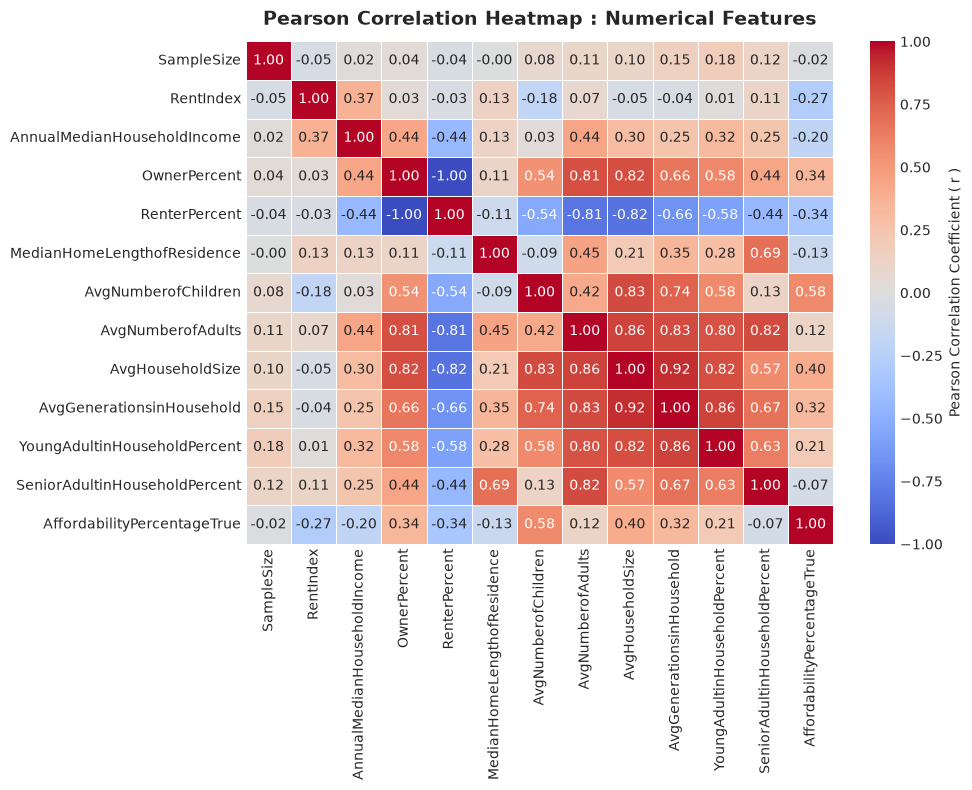

In [28]:
plt.figure (figsize = (10 , 8))

sns.heatmap (
    corr_matrix ,
    annot = True ,
    fmt = ".2f" ,
    cmap = "coolwarm" ,
    vmin = -1.0 ,
    vmax = 1.0 ,
    linewidths = 0.5 ,
    cbar_kws = {"label" : "Pearson Correlation Coefficient ( r )"}
)

plt.title("Pearson Correlation Heatmap : Numerical Features", fontsize = 14, fontweight = 'bold', pad =12)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "numerical_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [29]:
predictor_corr = corr_matrix.drop(
    index='AffordabilityPercentageTrue',
    columns='AffordabilityPercentageTrue'
)

upper_triangle = predictor_corr.where(
    np.triu(np.ones(predictor_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

high_corr_pairs = (
    high_corr_pairs[
        high_corr_pairs['Correlation'].abs() >= 0.80
    ]
    .sort_values(
        'Correlation',
        key=abs,
        ascending=False
    )
    .reset_index(drop=True)
)

display(high_corr_pairs.round(3))

,Feature 1,Feature 2,Correlation
0,OwnerPercent,RenterPercent,-1.000
1,AvgHouseholdSize,AvgGenerationsinHousehold,0.921
2,AvgNumberofAdults,AvgHouseholdSize,0.857
3,AvgGenerationsinHousehold,YoungAdultinHouseholdPercent,0.855
4,AvgNumberofChildren,AvgHouseholdSize,0.826
5,AvgNumberofAdults,AvgGenerationsinHousehold,0.825
6,AvgNumberofAdults,SeniorAdultinHouseholdPercent,0.821
7,RenterPercent,AvgHouseholdSize,-0.820
8,OwnerPercent,AvgHouseholdSize,0.820
9,AvgHouseholdSize,YoungAdultinHouseholdPercent,0.817


AvgNumberofChildren exhibits the strongest positive correlation with housing affordability, while RentIndex shows the strongest negative correlation. Several household demographic features also demonstrate strong intercorrelations, suggesting potential multicollinearity. These relationships will be considered during feature selection and model development.